Dataset link => https://www.kaggle.com/datasets/rakeshrau/social-network-ads

In [28]:
import numpy as np
import pandas as pd
import time

#Gradient descent is basically divided into 3 types depending data rate.

i) Batch GD (BGD)

ii) stochastics GD (SGD)

iii) Mini batch GD(middle of BGD and SGD)


fast -> BGD > MBGD > SGD

convergence -> BGD < MBGD < SGD

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
df= pd.read_csv('/content/drive/MyDrive/DL/dataset/Social_Network_Ads.csv')

In [31]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [32]:
df = df[['Age','EstimatedSalary','Purchased']]

In [33]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [34]:
X= df.drop('Purchased',axis=1)
y= df['Purchased']

In [35]:
X

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000
...,...,...
395,46,41000
396,51,23000
397,50,20000
398,36,33000


In [36]:
y

,Purchased
0,0
1,0
2,0
3,0
4,0
...,...
395,1
396,1
397,1
398,0


In [37]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [38]:
X_scaled.shape

(400, 2)

In [39]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [40]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [41]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 151 (604.00 B)

 Trainable params: 151 (604.00 B)

 Non-trainable params: 0 (0.00 B)

# This is stochastics gradient descent (batch_size = 1)

In [48]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
#start = time.time()
history = model.fit(X_scaled,y,epochs=100,batch_size=1,validation_split=0.2)
#print(time.time() - start)

Epoch 1/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8219 - loss: 0.5118 - val_accuracy: 0.7625 - val_loss: 0.5631
Epoch 2/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8375 - loss: 0.3707 - val_accuracy: 0.7375 - val_loss: 0.4833
Epoch 3/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8375 - loss: 0.3194 - val_accuracy: 0.7625 - val_loss: 0.4317
Epoch 4/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8438 - loss: 0.3016 - val_accuracy: 0.8000 - val_loss: 0.3989
Epoch 5/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8531 - loss: 0.2932 - val_accuracy: 0.8125 - val_loss: 0.3695
Epoch 6/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8594 - loss: 0.2914 - val_accuracy: 0.8625 - val_loss: 0.3550
Epoch 7/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8594 - loss: 0.2879 - val_accuracy: 0.9000 - val_loss: 0.3315
Epoch 8/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8656 - loss: 0.2859 - val_accu

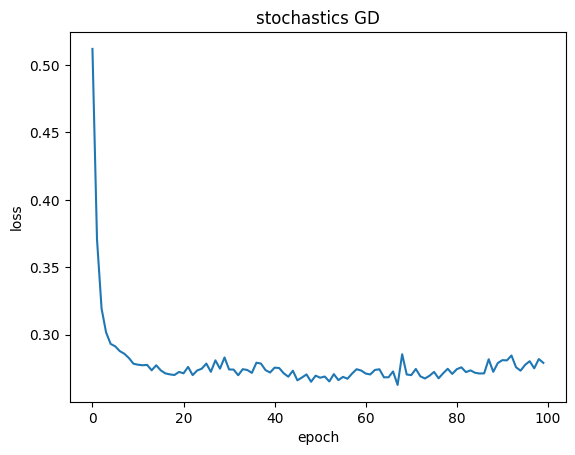

In [49]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.title('stochastics GD')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.show()

In [50]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# This batch gradient D because batch_size == n (400)
here used 150. we can use 400

In [53]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
#start = time.time()
history = model.fit(X_scaled,y,epochs=10,batch_size=150,validation_split=0.2)
#print(time.time() - start)

Epoch 1/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 187ms/step - accuracy: 0.3125 - loss: 0.7752 - val_accuracy: 0.7250 - val_loss: 0.5901
Epoch 2/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3469 - loss: 0.7467 - val_accuracy: 0.7750 - val_loss: 0.5889
Epoch 3/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3844 - loss: 0.7293 - val_accuracy: 0.8125 - val_loss: 0.5884
Epoch 4/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4031 - loss: 0.7154 - val_accuracy: 0.8375 - val_loss: 0.5875
Epoch 5/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4219 - loss: 0.7007 - val_accuracy: 0.8625 - val_loss: 0.5864
Epoch 6/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4406 - loss: 0.6889 - val_accuracy: 0.9000 - val_loss: 0.5856
Epoch 7/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4781 - loss: 0.6789 - val_accuracy: 0.9000 - val_loss: 0.5846
Epoch 8/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5406 - loss: 0.6677 - val_accuracy: 0.9125 - val_loss: 0.5848

Note

# what if batch_size doesn't divide no of rows properly?

e.g: 400/150 = 2.66
batch will divide into 3 parts 150,150,100(rest of the batch will be single batch)

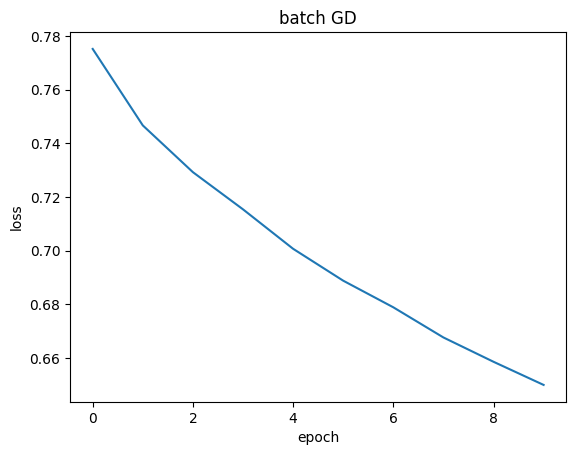

In [54]:
plt.plot(history.history['loss'])
plt.title('batch GD')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.show()